In [3]:
import sys
sys.path.append('../Utils')
sys.path.append('../Data')
sys.path.insert(0, '../../FRLC/src/')

from objective import solve_V_all_slices, tune_lam
from simulations import create_realistic_data, visualize_all
from plot_utils import plot_slices_horizontal_centered, plot_mass_transport_heatmap, plot_gene_panels, panel
from metrics import cluster_compute_ari_and_plot
from prepare_arista import prepare_data

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
from scipy.optimize import minimize_scalar

import torch

# if torch.cuda.is_available():
#     from objective_cuda import solve_V_all_slices_torch as solve_V_all_slices
# else:
    
from objective import solve_V_all_slices


%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Load data. 

Change fname according to local directories. The data is downloaded from:
https://db.cngb.org/stomics/datasets/STDS0000056

The resulting adata_insamp is a list of adata objects containing spatial transcriptomics. pd_B is the reference matrix representing mean expression for cell types. 

In [11]:
adata_insamp, pd_B = prepare_data(threshold=1.25, return_sc=False, data_dir = '../../../Data/ARISTA/', renormalize=False, reference_subset=True)

loaded DPI2
loaded DPI5
loaded DPI10


/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_arista.py:408: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  dpi15_rep3.X = dpi15_rep3.layers["counts"].copy()


loaded DPI15
loaded DPI20
loaded DPI30


/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_arista.py:440: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata = sc.concat((dpi2_rep1, dpi5_rep1, dpi10_rep1, dpi15_rep3, dpi20_rep2, dpi30))


loaded DPI2
loaded DPI5
loaded DPI10


/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_arista.py:304: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  dpi15_rep4.X = dpi15_rep4.layers["counts"].copy()


loaded DPI15
loaded DPI20


/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_arista.py:324: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata = sc.concat((dpi2_rep2, dpi5_rep2, dpi10_rep2, dpi15_rep4, dpi20_rep3))


In [12]:
time = [2, 5, 10, 15, 20, 30]
torch.manual_seed(0); torch.cuda.manual_seed_all(0)
lam, _, _ = tune_lam(adata_insamp, pd_B, target_spatial_ratio=0.02)
V, pi, aux = solve_V_all_slices(
                        adata_insamp, pd_B,
                        lam = lam,
                        verbose=True,
                        ot_solver='low_rank',
                        alpha = 0.5,
                    )

=== tune_lam: sweeping lam with mu=-1, target spatial_ratio=0.02 ===
total data variance = 1.223574e+09
  lam=0          D=4.361143e+08  spatial_ratio=0.000000e+00
  lam=1          D=4.361143e+08  spatial_ratio=1.215419e-05
  lam=3          D=4.361141e+08  spatial_ratio=3.645716e-05
  lam=10         D=4.361142e+08  spatial_ratio=1.214606e-04
  lam=30         D=4.361138e+08  spatial_ratio=3.638225e-04
  lam=100        D=4.361098e+08  spatial_ratio=1.203801e-03
  lam=300        D=4.361042e+08  spatial_ratio=3.424149e-03
  lam=1000       D=4.364003e+08  spatial_ratio=9.578129e-03
  lam=3000       D=4.377120e+08  spatial_ratio=2.261772e-02
  -> crossed target_spatial_ratio=0.02 between lam=1000 and lam=3000; closest is lam=3000
tune_lam chosen lam* = 3000.0

lambda used = 3.000000e+03 (fixed)
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteratio

In [13]:


import matplotlib.pyplot as plt
ari, nmi, true_labels, pred_labels = cluster_compute_ari_and_plot(
            np.vstack(V),
            ad.concat(adata_insamp),
            celltype_key="cellType",
            embedding_key="spatial",
            clustering="leiden",
            plot=False,
            auto_resolution=True,
            random_state = 0
            
            # resolution_grid=np.linspace(0.01,2,50),

)

n_spots = np.cumsum([0] + [adt.n_obs for adt in adata_insamp])
for i, adt in enumerate(adata_insamp):
    adt.obs['pred_label'] = pd.Categorical(pred_labels[n_spots[i]:n_spots[i + 1]])

print('ari='+str(ari))
print('nmi='+str(nmi))


clustering at resolution=0.5 has been done! Found 20 clusters.
clustering at resolution=1.5 has been done! Found 42 clusters.
clustering at resolution=1.0 has been done! Found 32 clusters.
clustering at resolution=0.75 has been done! Found 28 clusters.
clustering at resolution=0.625 has been done! Found 25 clusters.
clustering at resolution=0.6875 has been done! Found 29 clusters.
clustering at resolution=0.65625 has been done! Found 24 clusters.
clustering at resolution=0.671875 has been done! Found 24 clusters.
clustering at resolution=0.6796875 has been done! Found 26 clusters.
clustering at resolution=0.68359375 has been done! Found 25 clusters.
clustering at resolution=0.685546875 has been done! Found 25 clusters.
clustering at resolution=0.6865234375 has been done! Found 29 clusters.
Leiden: target_k=27, best_resolution=0.750, n_clusters=28
ari=0.2587649875067505
nmi=0.49304089997585315


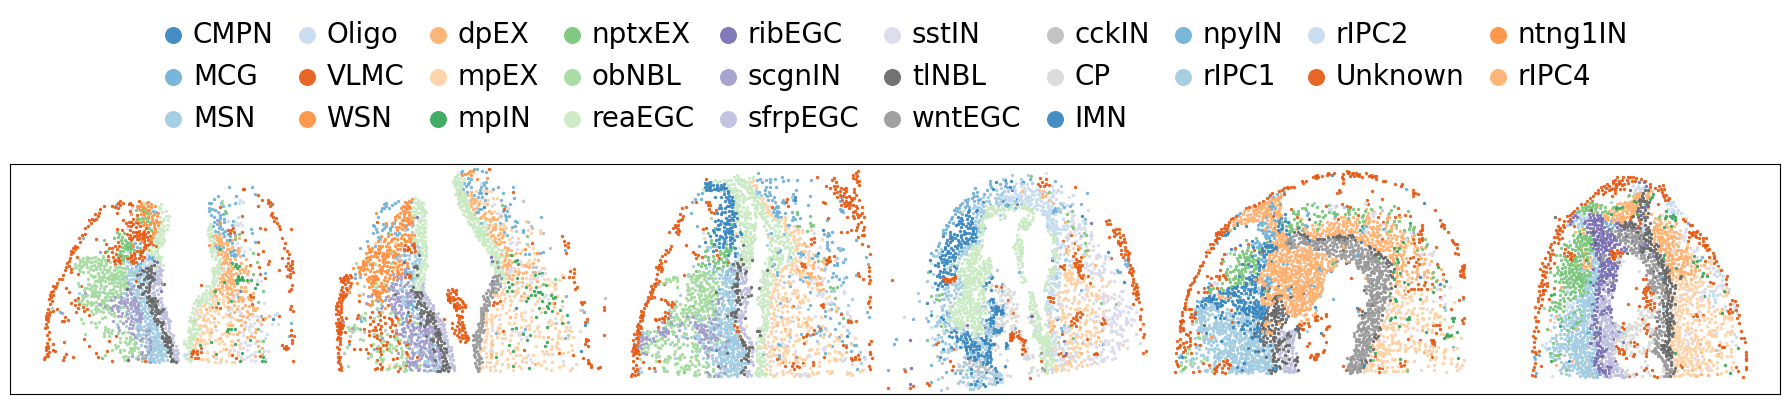

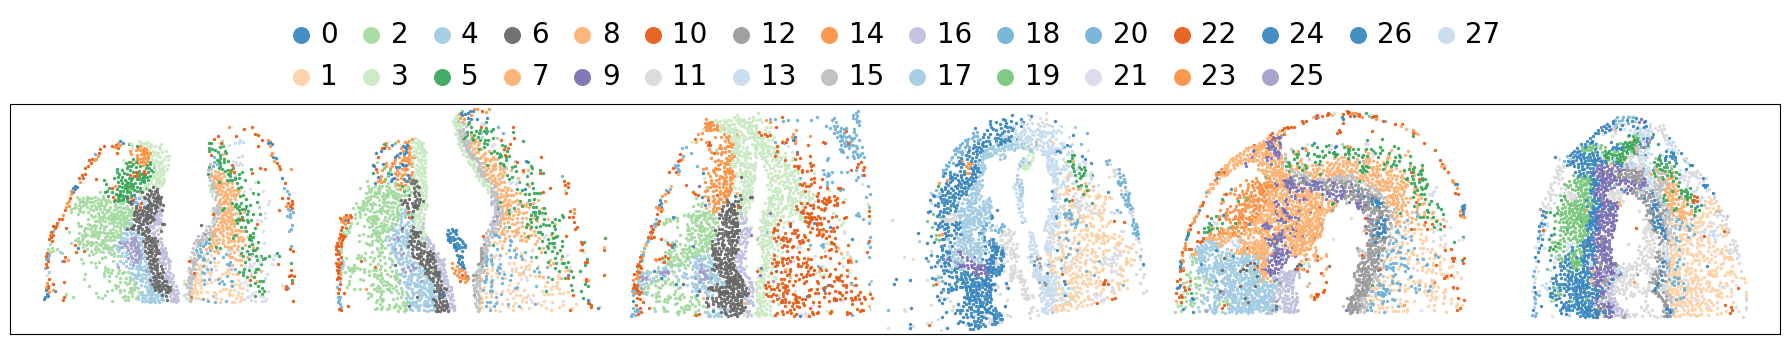

In [14]:
cmap = 'tab20c'
fig, ax = plot_slices_horizontal_centered(
    adata_list=adata_insamp,
    obs_key="cellType",
    coord_keys=("x", "y"),      # uses ad.obs['x'], ad.obs['y'] if present
    obsm_key="spatial",         # otherwise uses ad.obsm['spatial'][:, :2]
    order_key=None,     # optional; requires each slice has exactly one time_point
    # order_map={"E10.5": 10.5, "E11.5": 11.5},  # optional helper
    y_scale=1.0,
    x_gap = 350,
    s=6,
    legend_loc='upper center',
    legend_bbox=(0.5,0.95),
    legend_ncol = 10,
    legend_font=20,
    truth_cmap=cmap,
    truth_key="cellType",
)

cmap = 'tab20c'
fig, ax = plot_slices_horizontal_centered(
    adata_list=adata_insamp,
    obs_key="pred_label",
    coord_keys=("x", "y"),      # uses ad.obs['x'], ad.obs['y'] if present
    obsm_key="spatial",         # otherwise uses ad.obsm['spatial'][:, :2]
    order_key=None,     # optional; requires each slice has exactly one time_point
    # order_map={"E10.5": 10.5, "E11.5": 11.5},  # optional helper
    y_scale=1.0,
    x_gap = 350,
    s=6,
    legend_loc='upper center',
    legend_bbox=(0.5,0.85),
    legend_ncol = 15,
    legend_font=20,
    truth_cmap=cmap,
    truth_key="cellType",
)

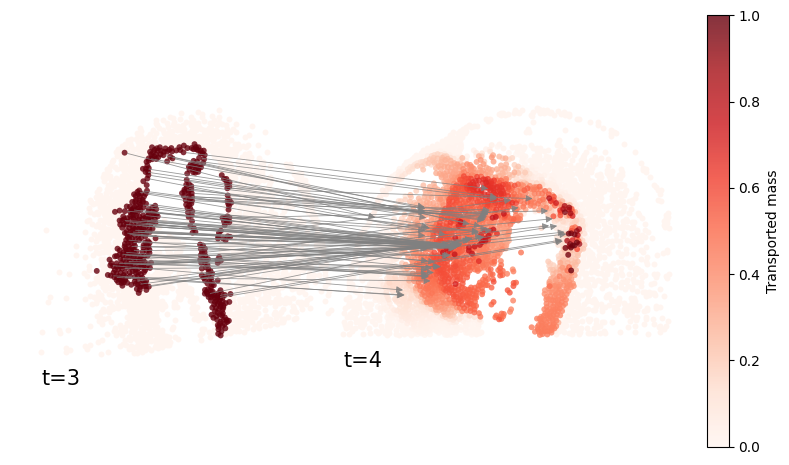

In [15]:
import math


pi_dense = [p.toarray() if sp.issparse(p) else np.asarray(p) for p in pi]

    
fig, _, _ = plot_mass_transport_heatmap(
        adata_insamp,
        V,
        pi_dense,
        t_start=3,
        t_end=4,
        source_celltype='reaEGC',
        celltype_obs_key="cellType",
        source_mass_source="obs",
        y_gap=3000,
        y_scale=1.0,
        show_edges=True,
        n_sources_show = 100,
        alpha=0.8,
        cmap="Reds",
        edge_alpha=0.8,           
       
)

# fig.show()


# For this data we also demonstrate the downstreams

In [16]:
from plot_utils import plot_V_dotplot_from_adata
from downstream import region_de_wilcoxon, clean_gene_for_enrichr, plot_gene_lollipop_by_region
from downstream import make_gene_name_table, add_parsed_gene_names_to_de, compute_gene_region_summary

## Task 1 (straightforward): temporal variation in the population and cell type program magnitude varying over time

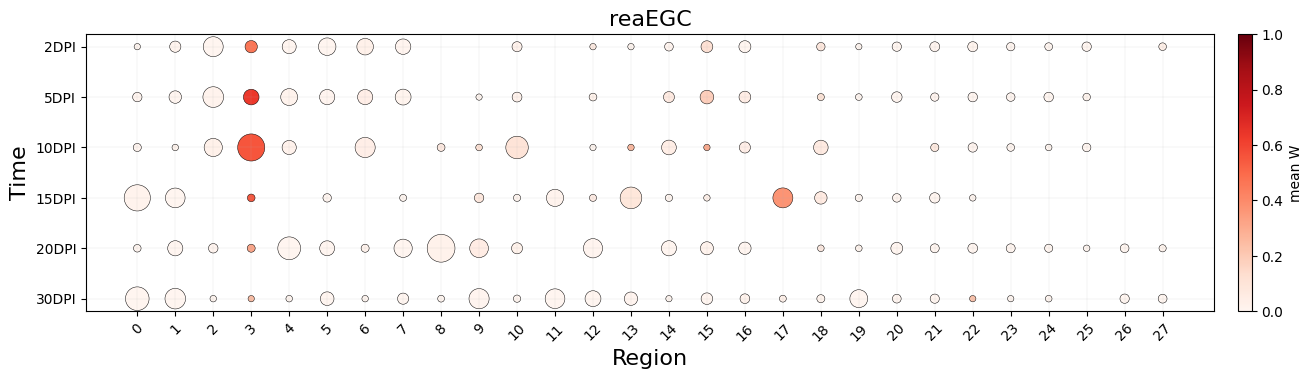

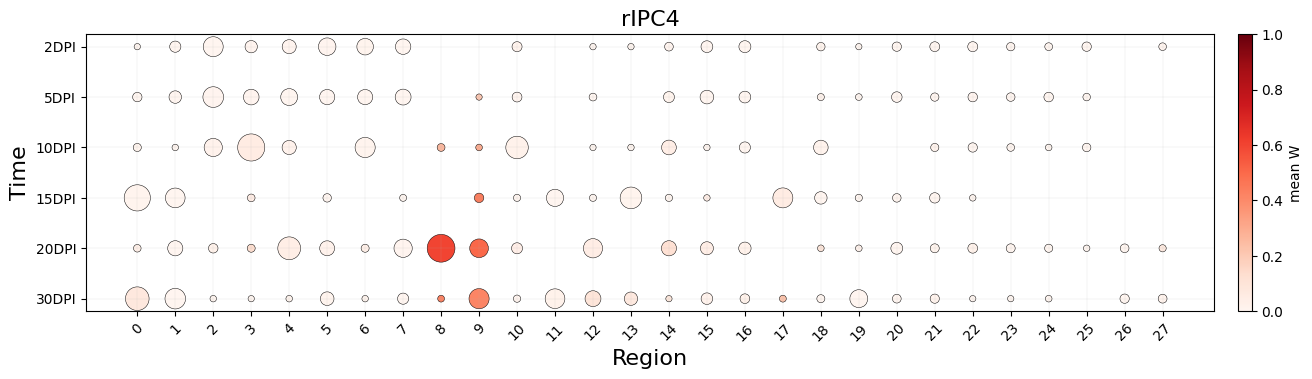

In [17]:
celltype_order = pd_B.index.to_list()
fig = plot_V_dotplot_from_adata(
    adata_list=adata_insamp,
    V_list=V,
    celltype="reaEGC",
    celltype_names=celltype_order,
    region_key="pred_label",
    times=[str(t)+'DPI' for t in time],
    agg="mean",
    cmap="Reds",
)

fig = plot_V_dotplot_from_adata(
    adata_list=adata_insamp,
    V_list=V,
    celltype="rIPC4",
    celltype_names=celltype_order,
    region_key="pred_label",
    times=[str(t)+'DPI' for t in time],
    agg="mean",
    cmap="Reds",
)

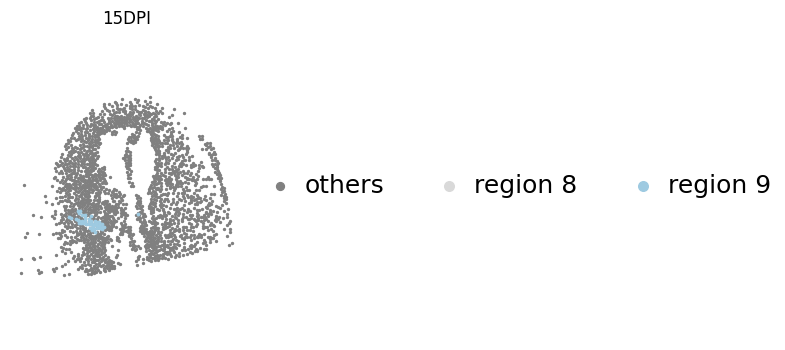

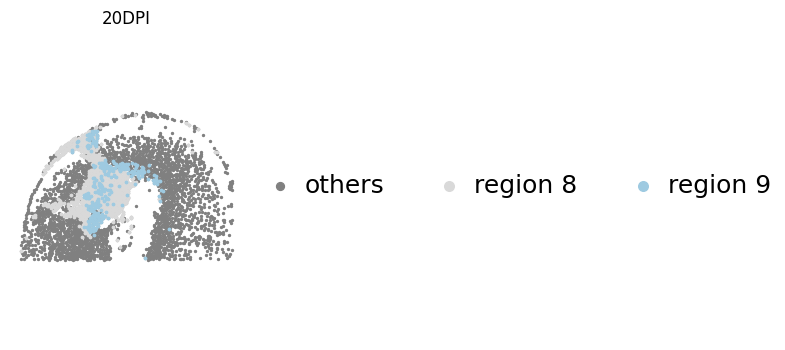

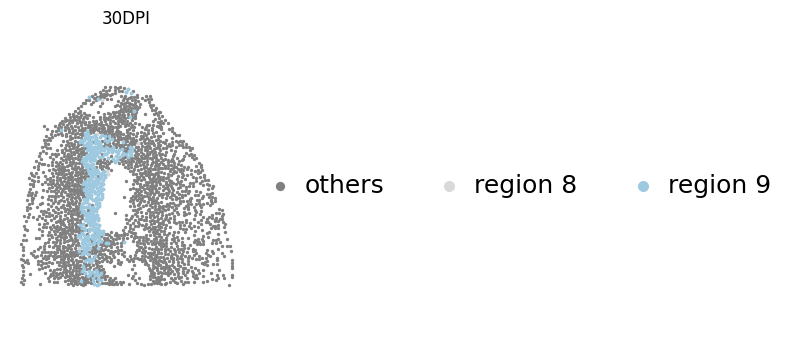

In [18]:
plt.rcParams['figure.figsize'] = (3,4)
cmap = plt.get_cmap("tab20c")
colors = cmap(np.linspace(0, 11/20, 20))

for t in [3,4,5]:
    plt.scatter(adata_insamp[t].obs['x'], adata_insamp[t].obs['y'], c='gray', s=2, label='others')
    plt.scatter(adata_insamp[t][adata_insamp[t].obs["pred_label"] == 8].obs['x'], adata_insamp[t][adata_insamp[t].obs["pred_label"] == 8].obs['y'], s=3,  color="#d9d9d9", label='region 8')
    plt.scatter(adata_insamp[t][adata_insamp[t].obs["pred_label"] == 9].obs['x'], adata_insamp[t][adata_insamp[t].obs["pred_label"] == 9].obs['y'], s=3,  color="#9ecae1",  label='region 9')

    plt.axis('equal')
    plt.axis('off')
    plt.legend(
        frameon=False,
        fontsize=18,
        markerscale=4,      # makes legend dots larger
        handlelength=1.2,
        handletextpad=0.4,
        borderpad=0.2,
        labelspacing=0.5,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        ncol=3
    )
    plt.title(str(time[t])+'DPI')
    plt.show()

## Task 2: nominate differentially expressed marker genes, and make a lollipop plot for each

In [19]:
de_df = region_de_wilcoxon(
    ad.concat(adata_insamp),
    region_key="pred_label",
    layer=None,
    min_region_size=10,
    min_frac=0.05,
    genes = pd_B.columns
)

Renormalizing from layers['counts'] (target_sum=10000, log1p for tests).
  Testing 9194 of the supplied genes.
Computing region 0...
Computing region 1...
Computing region 2...
Computing region 3...
Computing region 4...
Computing region 5...
Computing region 6...
Computing region 7...
Computing region 8...
Computing region 9...
Computing region 10...
Computing region 11...
Computing region 12...
Computing region 13...
Computing region 14...
Computing region 15...
Computing region 16...
Computing region 17...
Computing region 18...
Computing region 19...
Computing region 20...
Computing region 21...
Computing region 22...
Computing region 23...
Computing region 24...
Computing region 25...
Computing region 26...
Computing region 27...


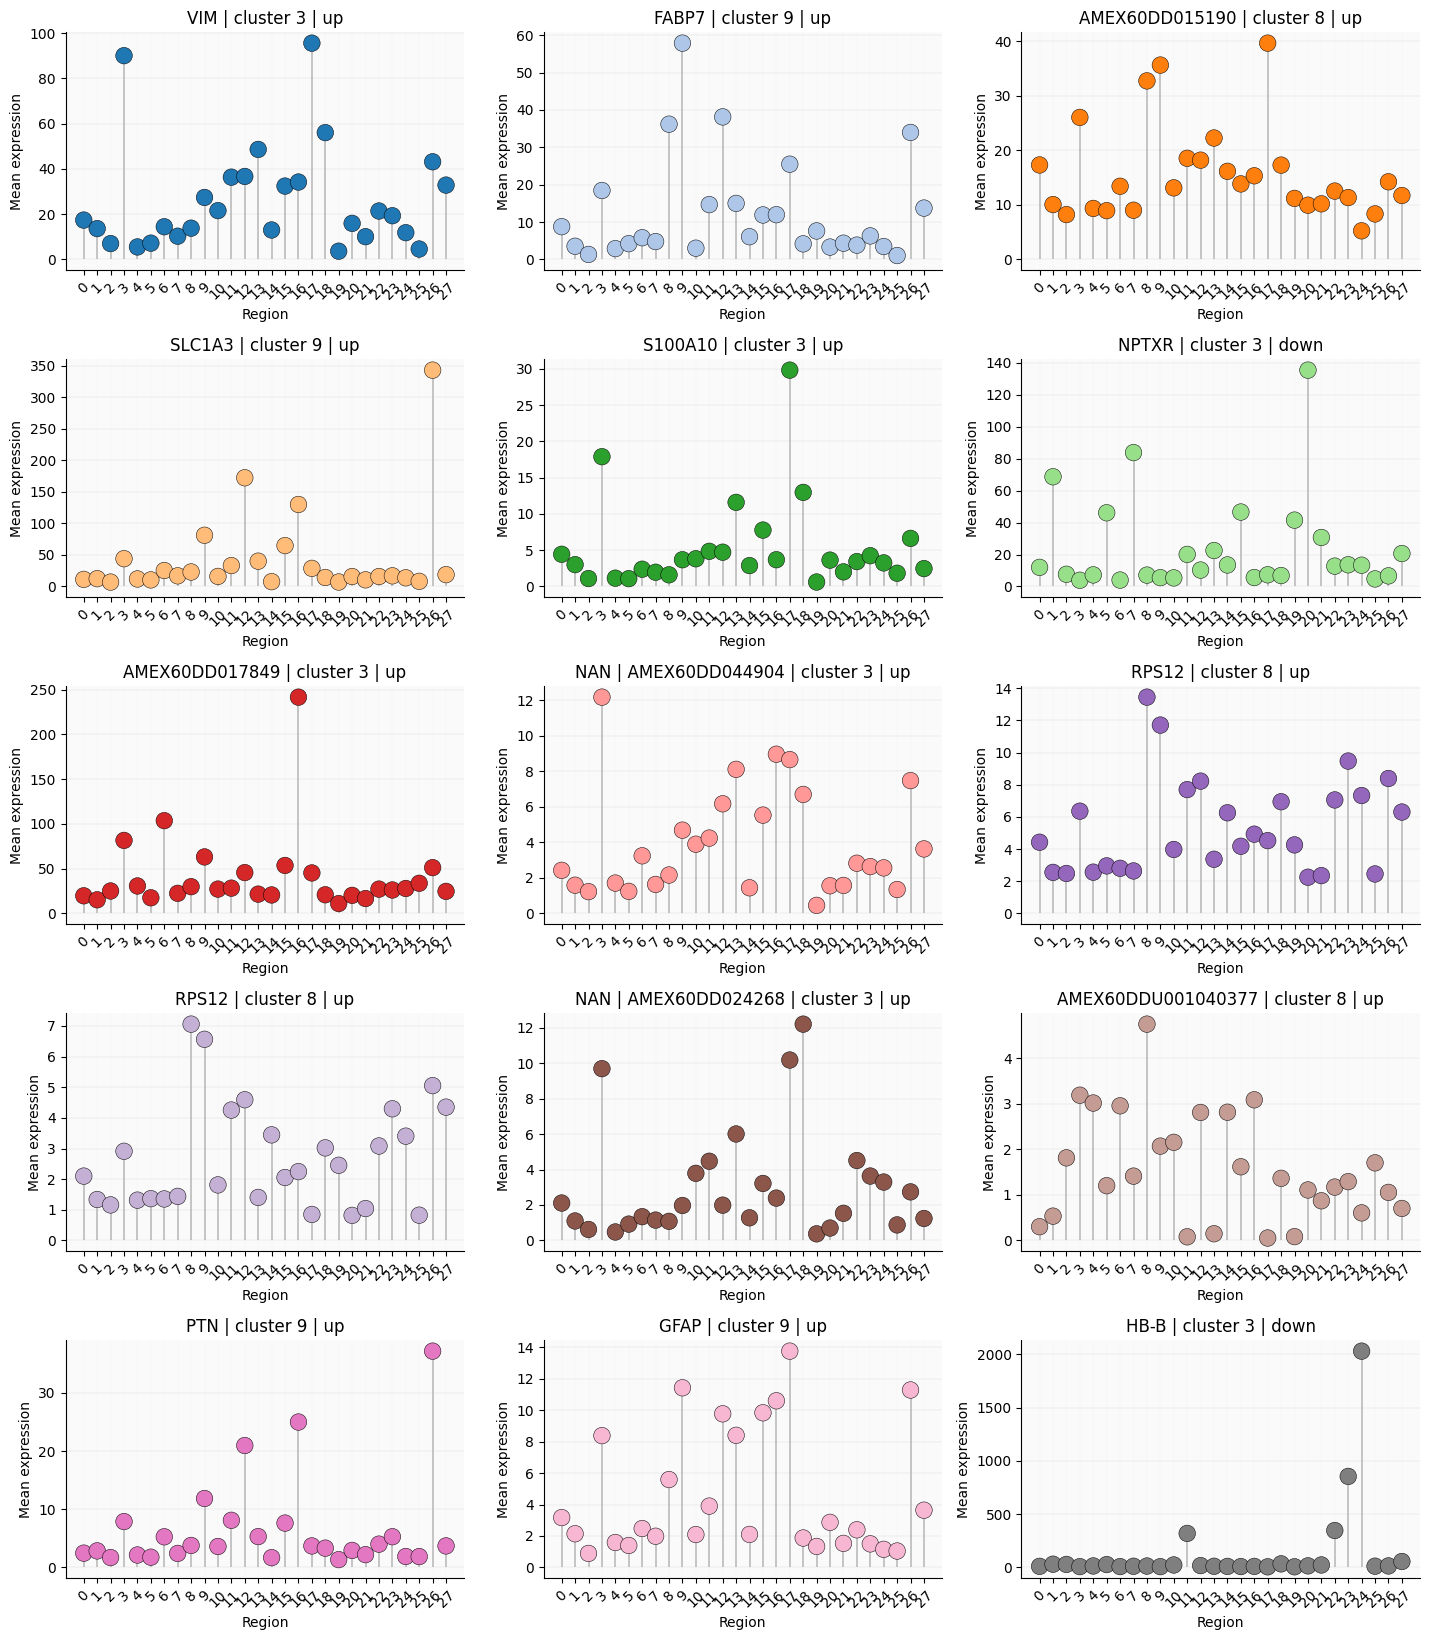

In [20]:
gene_table = make_gene_name_table(de_df["gene"].unique())
de_df_go = add_parsed_gene_names_to_de(de_df)

regions_of_interest = ['3', '8', '9'] 

top = (
    de_df_go
    .assign(region=lambda d: d["region"].astype(str),
            abs_log2fc=lambda d: d["log2fc"].abs(),
            direction=lambda d: np.where(d["log2fc"] >= 0, "up", "down"))
    .query("region in @regions_of_interest and p_adj < 0.05 and abs_log2fc > 0.25")
    .sort_values(["p_adj", "abs_log2fc"], ascending=[True, False])
    .drop_duplicates("gene")
    .head(15)
    .set_index("gene")
)

top["label"] = (top["human_symbol"].fillna(pd.Series(top.index, index=top.index))
                .map(clean_gene_for_enrichr)
                .fillna(pd.Series(top.index, index=top.index)))

fig, axes, df = plot_gene_lollipop_by_region(
    ad.concat(adata_insamp),
    genes=top.index.tolist(),
    region_key="pred_label",
    color_by="gene",
    gene_direction_map=top["direction"].to_dict(),
    gene_region_map=top["region"].to_dict(),
    gene_label_map=top["label"].to_dict(),
)
plt.show()

## Task 3: use genes above for GO enrichment analysis (via enrichr)

Running GO for region 3: 91 genes
Region 3: 1308 terms returned
Running GO for region 8: 95 genes
Region 8: 1028 terms returned
Running GO for region 9: 107 genes
Region 9: 1233 terms returned
Running GO for region 3: 49 genes
Region 3: 604 terms returned
Running GO for region 8: 40 genes
Region 8: 731 terms returned
Running GO for region 9: 28 genes
Region 9: 316 terms returned


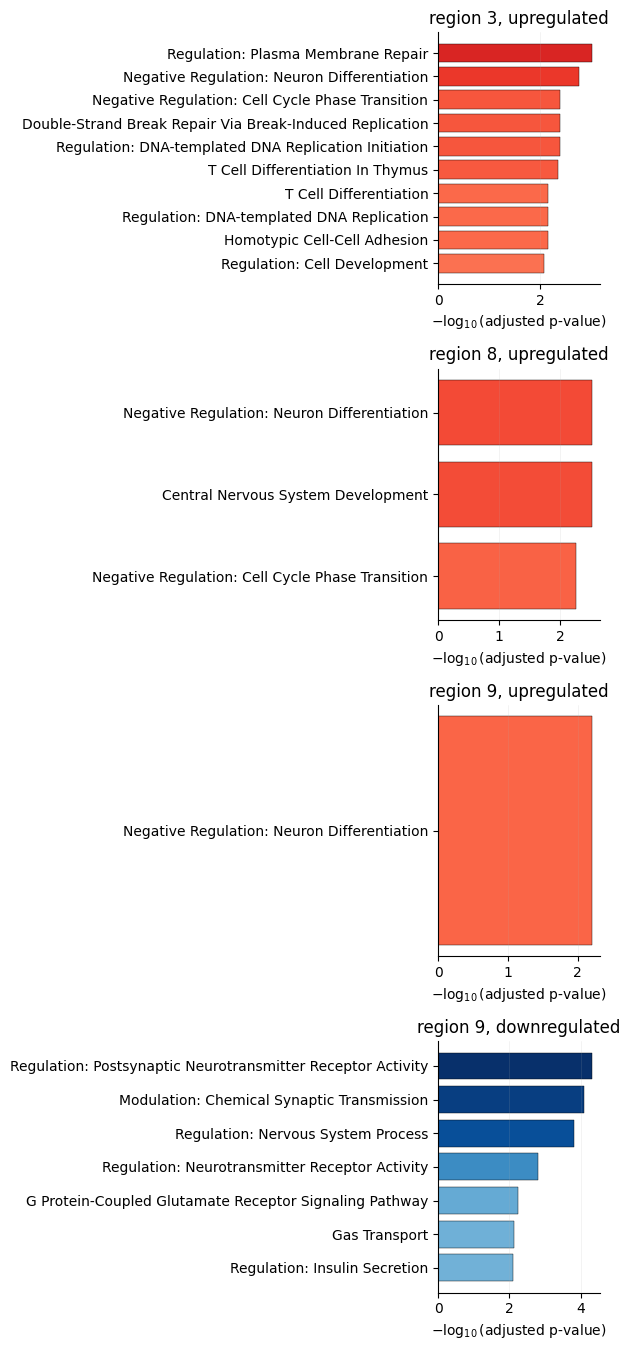

In [21]:
from downstream import (
    add_parsed_gene_names_to_de, get_region_marker_human_symbols,
    run_go_enrichr_by_region, plot_go_barplot_by_region,
)


de_df_go = add_parsed_gene_names_to_de(de_df)
_, marker_df = get_region_marker_human_symbols(
    de_df_go, regions_of_interest, p_adj_cutoff=0.05, log2fc_cutoff=0.25
)

frames = []
for direction in ("up", "down"):
    sub = marker_df[marker_df["direction"] == direction]
    markers = {
        str(r): g["human_symbol"].map(clean_gene_for_enrichr).dropna().unique().tolist()
        for r, g in sub.groupby(sub["region"].astype(str))
    }
    go = run_go_enrichr_by_region(
        {r: g for r, g in markers.items() if len(g) >= 5},
        organism="homo sapiens", cutoff=0.5,
    )
    if not go.empty:
        frames.append(go.assign(direction=direction))

go_df = pd.concat(frames, ignore_index=True)
go_df = go_df[go_df["Adjusted P-value"] < 0.01]
go_df["region"] = go_df["region"].astype(str)

fig, axes, _ = plot_go_barplot_by_region(
    go_df, regions_of_interest, top_n=10, directions=("up", "down")
)
plt.show()

## Task 4: Plot transition table (an educated guess of where rIPC cells could have come from via OT)

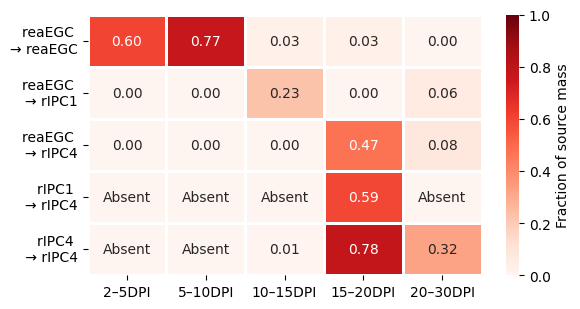

In [25]:
from downstream import add_cluster_annotation_from_V, compute_transition_tables_from_couplings

edges = [("reaEGC", "reaEGC"), ("reaEGC", "rIPC1"),("reaEGC", "rIPC4"),
         ("rIPC1", "rIPC4"), ("rIPC4", "rIPC4")]
edge_names = ["reaEGC \n→ reaEGC","reaEGC \n→ rIPC1", "reaEGC \n→ rIPC4",
              "rIPC1 \n→ rIPC4", "rIPC4 \n → rIPC4"]
intervals = ["2–5DPI", "5–10DPI", "10–15DPI", "15–20DPI", "20–30DPI"]

adata_insamp = [
    add_cluster_annotation_from_V(a, v, celltype_order=celltype_order,
                                  cluster_key="pred_label",
                                  key_added="cluster_annotated_celltype")
    for a, v in zip(adata_insamp, V)
]

tables, _ = compute_transition_tables_from_couplings(
    adata_insamp, pi, celltype_key="cluster_annotated_celltype", normalize="total"
)

# NaN where the source is absent, so it's distinct from "went nowhere"
frac = [t.div(t.sum(axis=1).replace(0, np.nan), axis=0) for t in tables]
df = pd.DataFrame(
    [[f.loc[s, tg] if s in f.index and tg in f.columns else np.nan
      for s, tg in edges] for f in frac],
    index=intervals, columns=edge_names,
).T

fig, ax = plt.subplots(figsize=(6, 3.2))
sns.heatmap(df.fillna(0), ax=ax, cmap="Reds", vmin=0, vmax=1,
            annot=df.map(lambda v: "Absent" if pd.isna(v) else f"{v:.2f}"),
            fmt="", linewidths=1, linecolor="white",
            cbar_kws={"label": "Fraction of source mass"})
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()